# CCA_003 / CCA_004: BU vs BT on AZA_001

The switching directions of the AZA_001 rig (Alex Zirn, 2025-06-13), measured and fitted:

| direction | windows | Ar | He |
|---|---|---|---|
| BU | even | rise | fall |
| BT | odd | fall | rise |

| script | kernels | tracers |
|---|---|---|
| CCA_003 | one set E_up, E_down, E_cap for both directions (rows as deviation from the level before the step, smooth sin² start) | Ar, He, Ar+He |
| CCA_004 | as CCA_003, one set per direction (`Es BU`, `Es BT`), each fitted on its own direction's rows only | Ar, He, Ar+He |

The notebook picks up the newest run of each (script, tracers) combination in `Runs/` (untagged runs only); rerun it
after a new run. Shape metric as in CCA_002_overview: the unit step response of the section's chain (the kernels the
section was fitted with, the others at direct response, through nRTD) against the mean F of the measured rows of a
group, F = (x − x_before) / (x_after − x_before).

This notebook does not choose a fit.

In [1]:
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

REPO = (
    Path.cwd().resolve().parents[1]
    if Path.cwd().name == "CCA"
    else Path.cwd().resolve()
)
sys.path.insert(0, str(REPO / "lib"))
from nRTD.rtd_net import RTDNet

torch.set_default_dtype(torch.float64)
pd.set_option("display.width", 200)
RUNS = REPO / "Experiments" / "CCA" / "Runs"
SECTIONS = ("cap", "upstream", "total")
UP, DOWN, CAP = 0, 1, 2
CHAIN = {"cap": (CAP,), "upstream": (UP, CAP), "total": (UP, DOWN, CAP)}
KERNEL_TIMES = [(0.0, 20.0), (0.0, 45.0), (0.0, 20.0)]
DT = 0.25
T_STEP = 1.0  # all CCA windows put the step at 1.0 s
TRACER_SETS = {"He": ("He",), "Ar": ("Ar",), "ArHe": ("Ar", "He")}
LABEL = {"He": "He", "Ar": "Ar", "ArHe": "Ar+He"}

# newest untagged run per (script, tracers)
found = {}
for f in sorted(RUNS.glob("CCA_00[34]_*.npy")):
    m = re.fullmatch(
        r"(CCA_00[34])_(Ar|He|ArHe)_(\d{4}-\d{2}-\d{2}_\d{6})\.npy", f.name
    )
    if m:
        found[m[1], m[2]] = f
runs = {k: np.load(f, allow_pickle=True).item() for k, f in sorted(found.items())}
missing = [
    f"{s} {t}"
    for s in ("CCA_003", "CCA_004")
    for t in TRACER_SETS
    if (s, t) not in runs
]
complete = [t for t in TRACER_SETS if ("CCA_003", t) in runs and ("CCA_004", t) in runs]

# kernel sets per tracer set: CCA_003 (shared), CCA_004 BU, CCA_004 BT
KSETS = ("CCA_003", "CCA_004 BU", "CCA_004 BT")
kernels = {}
for t in complete:
    kernels[t, "CCA_003"] = runs["CCA_003", t]["Es"]
    kernels[t, "CCA_004 BU"] = runs["CCA_004", t]["Es BU"]
    kernels[t, "CCA_004 BT"] = runs["CCA_004", t]["Es BT"]

rows = []
for (script, t), r in runs.items():
    s = r["settings"]
    rows.append(
        {
            "script": script,
            "tracers": LABEL[t],
            "run": found[script, t].stem,
            "epochs/section": s["epochs_per_section"],
            "seed": s["seed"],
            "lr": s["lr"],
            "wall [s]": round(sum(s["wall_s"].values())),
            "nRTD": r["versions"]["nRTD"][:8],
        }
    )
print("missing runs:", missing or "none")
print("compared tracer sets:", [LABEL[t] for t in complete])
pd.DataFrame(rows)

missing runs: none
compared tracer sets: ['He', 'Ar', 'Ar+He']


,script,tracers,run,epochs/section,seed,lr,wall [s],nRTD
0,CCA_003,Ar,CCA_003_Ar_2026-10-31_135249,20000,0,0.004,147,31b36cea
1,CCA_003,Ar+He,CCA_003_ArHe_2026-10-31_135759,20000,0,0.004,223,31b36cea
2,CCA_003,He,CCA_003_He_2026-10-31_135523,20000,0,0.004,148,31b36cea
3,CCA_004,Ar,CCA_004_Ar_2026-11-02_140730,20000,0,0.004,239,46c4c20a
4,CCA_004,Ar+He,CCA_004_ArHe_2026-11-02_141140,20000,0,0.004,290,46c4c20a
5,CCA_004,He,CCA_004_He_2026-11-02_140302,20000,0,0.004,256,46c4c20a


## 1. Same data in all runs?

Reference: CCA_003 Ar+He (all 20 / 48 / 48 rows). Every other run's rows (original levels) must equal the matching
rows there, and the BU/BT labels of CCA_004 must match the window parity.

In [2]:
ref = runs["CCA_003", "ArHe"]
ROWSEL = {"Ar": slice(0, None, 2), "He": slice(1, None, 2), "ArHe": slice(None)}
rows = []
for (script, t), r in runs.items():
    for s in SECTIONS:
        sel = ROWSEL[t]
        row = {
            "run": f"{script} {LABEL[t]}",
            "section": s,
            "max |Δ x_out|": np.abs(r[f"x_out {s}"] - ref[f"x_out {s}"][sel]).max(),
            "max |Δ x_in|": np.abs(r[f"x_in {s}"] - ref[f"x_in {s}"][sel]).max(),
        }
        if script == "CCA_004":
            parity = (np.arange(ref[f"x_out {s}"].shape[0])[sel] // 2) % 2
            row["direction labels ok"] = bool(
                (r[f"direction {s}"] == np.array(["BU", "BT"])[parity]).all()
            )
        rows.append(row)
pd.DataFrame(rows).pivot_table(index="run", columns="section", values="max |Δ x_out|")

section,cap,total,upstream
run,,,
CCA_003 Ar,0.0,0.0,0.0
CCA_003 Ar+He,0.0,0.0,0.0
CCA_003 He,0.0,0.0,0.0
CCA_004 Ar,0.0,0.0,0.0
CCA_004 Ar+He,0.0,0.0,0.0
CCA_004 He,0.0,0.0,0.0


In [3]:
pd.DataFrame(rows).dropna().groupby("run")["direction labels ok"].all()

run
CCA_004 Ar       True
CCA_004 Ar+He    True
CCA_004 He       True
Name: direction labels ok, dtype: bool

## 2. Measured data: BU vs BT

Mean F per group, its crossing times after the step and the repeat scatter. Per tracer, BU − BT is the difference
between the directions, to be read against the repeat scatter.

In [4]:
GROUPS = {
    "Ar rise": slice(0, None, 4),
    "Ar fall": slice(2, None, 4),
    "He rise": slice(3, None, 4),
    "He fall": slice(1, None, 4),
}
DIRECTION = {"Ar rise": "BU", "He fall": "BU", "Ar fall": "BT", "He rise": "BT"}
OF = {(g[:2], d): g for g, d in DIRECTION.items()}  # (tracer, direction) → group


def F_rows(r, s):
    x, y = r[f"x_in {s}"][:, 0], r[f"x_out {s}"][:, 0]
    return (y - x[:, :1]) / (x[:, -1:] - x[:, :1])


def crossings(t, F):
    return {
        f"t{int(l * 100)}": float(t[np.argmax(F > l)] - T_STEP) for l in (0.1, 0.5, 0.9)
    }


data, scatter = {}, {}
rows = []
for s in SECTIONS:
    t, F = ref[f"t_out {s}"][0], F_rows(ref, s)
    for g, sl in GROUPS.items():
        data[s, g], scatter[s, g] = F[sl].mean(axis=0), F[sl].std(axis=0)
        rows.append(
            {
                "section": s,
                "group": f"{g} ({DIRECTION[g]})",
                "rows": F[sl].shape[0],
                **crossings(t, data[s, g]),
                "repeat std (max)": scatter[s, g].max(),
            }
        )
print("crossing times in s after the step")
display(pd.DataFrame(rows).style.format(precision=3))

rows = []
for s in SECTIONS:
    t = ref[f"t_out {s}"][0]
    for tr in ("Ar", "He"):
        bu, bt = OF[tr, "BU"], OF[tr, "BT"]
        c_bu, c_bt = crossings(t, data[s, bu]), crossings(t, data[s, bt])
        rows.append(
            {
                "section": s,
                "tracer": tr,
                "max |F_BU − F_BT|": np.abs(data[s, bu] - data[s, bt]).max(),
                **{f"Δ{k} BU − BT [s]": c_bu[k] - c_bt[k] for k in c_bu},
                "repeat std (max of both)": max(
                    scatter[s, bu].max(), scatter[s, bt].max()
                ),
            }
        )
pd.DataFrame(rows).style.format(precision=3).set_caption(
    "BU vs BT in the measured data"
)

crossing times in s after the step


,section,group,rows,t10,t50,t90,repeat std (max)
0,cap,Ar rise (BU),5,0.750,1.000,4.000,0.048
1,cap,Ar fall (BT),5,0.750,1.250,4.500,0.137
2,cap,He rise (BT),5,0.750,1.250,3.750,0.140
3,cap,He fall (BU),5,0.750,1.250,3.500,0.068
4,upstream,Ar rise (BU),12,1.250,1.750,5.500,0.010
5,upstream,Ar fall (BT),12,1.250,1.750,6.250,0.012
6,upstream,He rise (BT),12,1.250,1.750,6.500,0.044
7,upstream,He fall (BU),12,1.250,1.750,6.250,0.040
8,total,Ar rise (BU),12,22.500,24.500,32.250,0.009
9,total,Ar fall (BT),12,22.750,24.750,30.750,0.013


,section,tracer,max |F_BU − F_BT|,Δt10 BU − BT [s],Δt50 BU − BT [s],Δt90 BU − BT [s],repeat std (max of both)
0,cap,Ar,0.123,0.000,-0.250,-0.500,0.137
1,cap,He,0.089,0.000,0.000,-0.250,0.140
2,upstream,Ar,0.085,0.000,0.000,-0.750,0.012
3,upstream,He,0.033,0.000,0.000,-0.250,0.044
4,total,Ar,0.066,-0.250,-0.250,1.500,0.013
5,total,He,0.102,-0.250,-0.250,1.250,0.055


## 3. Fit quality: shared kernels (CCA_003) vs one set per direction (CCA_004)

max |ΔF| and RMS ΔF of the unit step response against the mean data of each group over the 120 s window, for every
kernel set of a tracer set on the groups of its tracers. `CCA_004 own` is the direction's own kernels (BU kernels on
BU groups, BT kernels on BT groups), `CCA_004 other` the other direction's kernels on the same group (what sharing a
kernel would cost the CCA_004 way round).

In [5]:
def step_response(E, s):
    net = RTDNet(
        kernel_sizes=[np.asarray(e).size for e in E], kernel_times=KERNEL_TIMES
    )
    for i, conv in enumerate(net.conv_layers):
        if i in CHAIN[s]:
            conv.E = torch.tensor(np.asarray(E[i]))
        else:
            conv.set_to_direct_response()
    t_in = torch.tensor(ref[f"t_in {s}"][:1])
    x = (t_in >= T_STEP).double()[:, None, :]
    with torch.no_grad():
        y, _ = net(x, t_in)
    return y[0, 0].numpy()


resp = {
    (t, k, s): step_response(E, s) for (t, k), E in kernels.items() for s in SECTIONS
}
rows = []
for (t, k, s), S in resp.items():
    tt = ref[f"t_out {s}"][0]
    for g in GROUPS:
        if g[:2] not in TRACER_SETS[t]:
            continue
        d = S - data[s, g]
        role = (
            "CCA_003"
            if k == "CCA_003"
            else ("CCA_004 own" if k.endswith(DIRECTION[g]) else "CCA_004 other")
        )
        rows.append(
            {
                "tracers": LABEL[t],
                "section": s,
                "group": f"{g} ({DIRECTION[g]})",
                "kernels": role,
                "max": np.abs(d).max(),
                "rms": np.sqrt(np.mean(d**2)),
                "Δt50": crossings(tt, S)["t50"] - crossings(tt, data[s, g])["t50"],
            }
        )
quality = pd.DataFrame(rows)
order = ["CCA_003", "CCA_004 own", "CCA_004 other"]
for metric, fmt in (("max", "{:.3f}"), ("rms", "{:.4f}")):
    display(
        quality.pivot_table(
            index=["section", "group"],
            columns=["tracers", "kernels"],
            values=metric,
            sort=False,
        )
        .reindex(columns=[(LABEL[t], o) for t in complete for o in order])
        .style.format(fmt)
        .background_gradient(axis=None, cmap="Reds")
        .set_caption(f"{metric} |ΔF|")
    )

In [6]:
(
    quality.pivot_table(
        index=["section", "group"],
        columns=["tracers", "kernels"],
        values="Δt50",
        sort=False,
    )
    .reindex(columns=[(LABEL[t], o) for t in complete for o in order])
    .style.format("{:+.2f}")
    .set_caption("t50 fit − t50 data [s]")
)

## 4. Figures: He, Ar, Ar+He

One figure per tracer set. Top: mean data of the fitted groups (thin; BU solid, BT dashed) and the step response of
CCA_003 (black) and CCA_004 BU (red) / BT (purple). Middle: fit − mean data, CCA_003 against both directions (black:
BU, grey: BT) and each CCA_004 set against its own direction (Ar solid, He dotted). Bottom: the kernels.

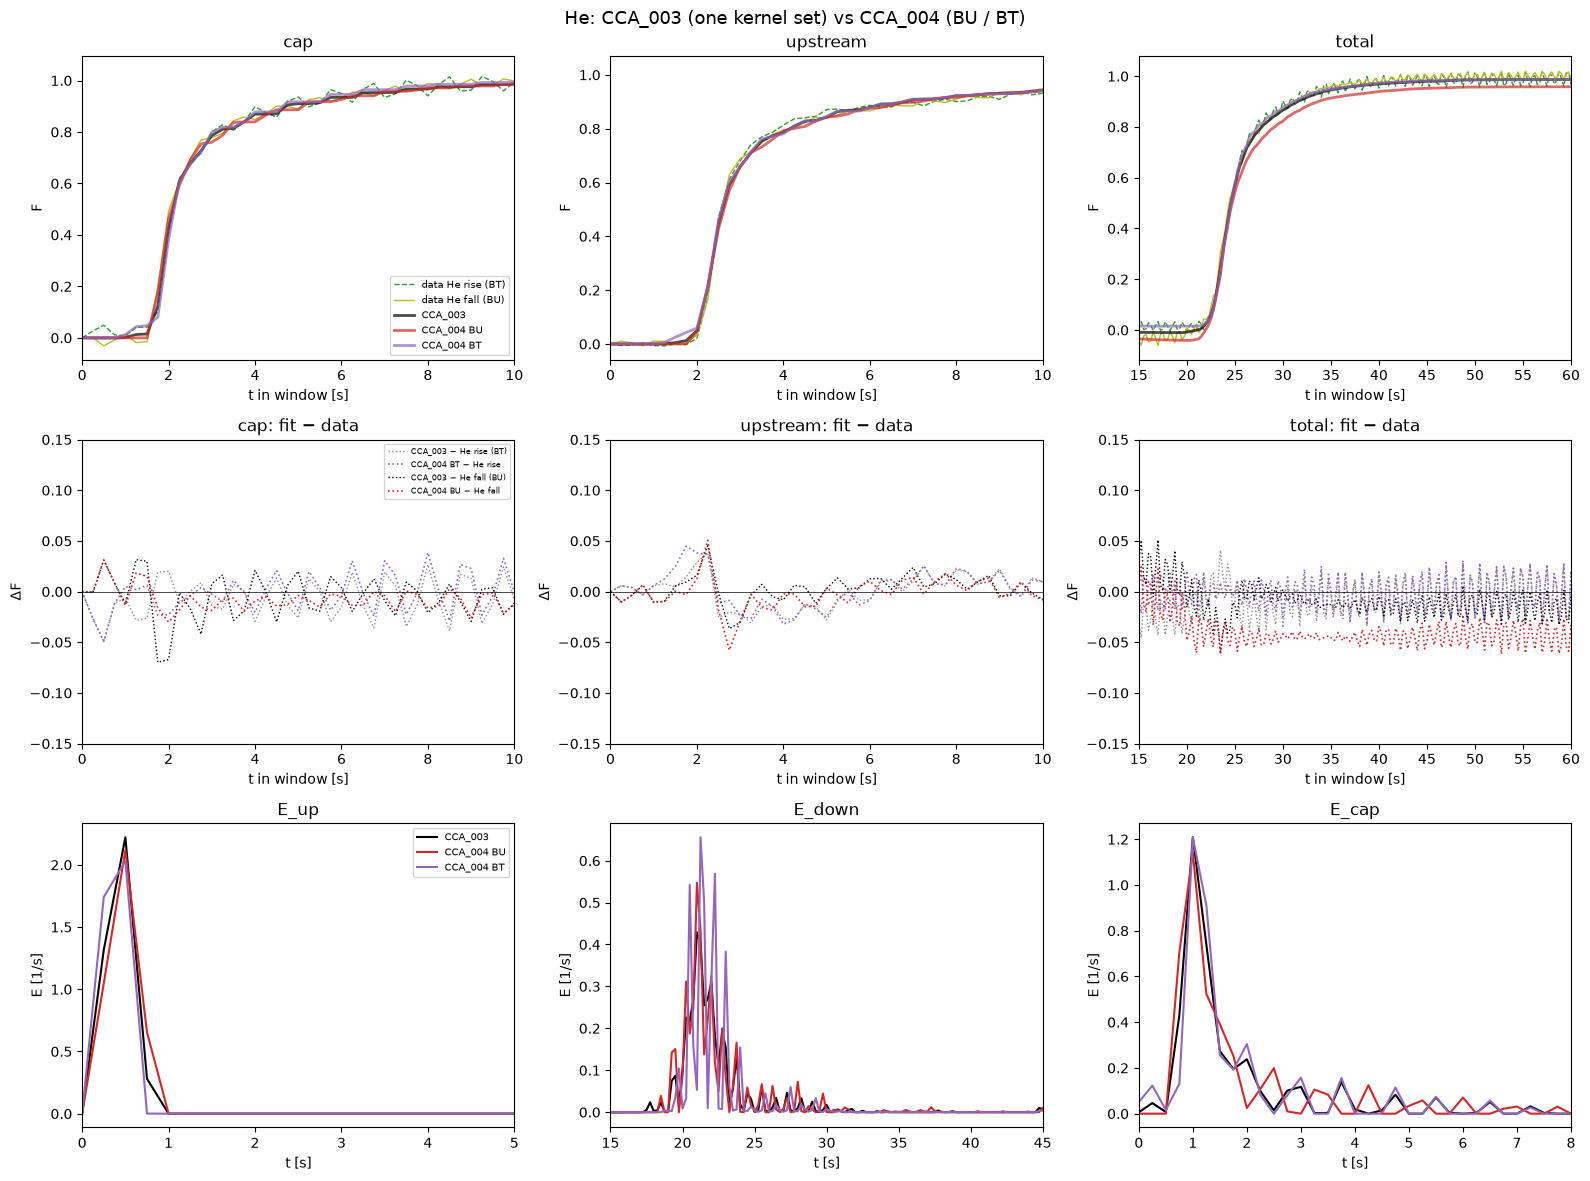

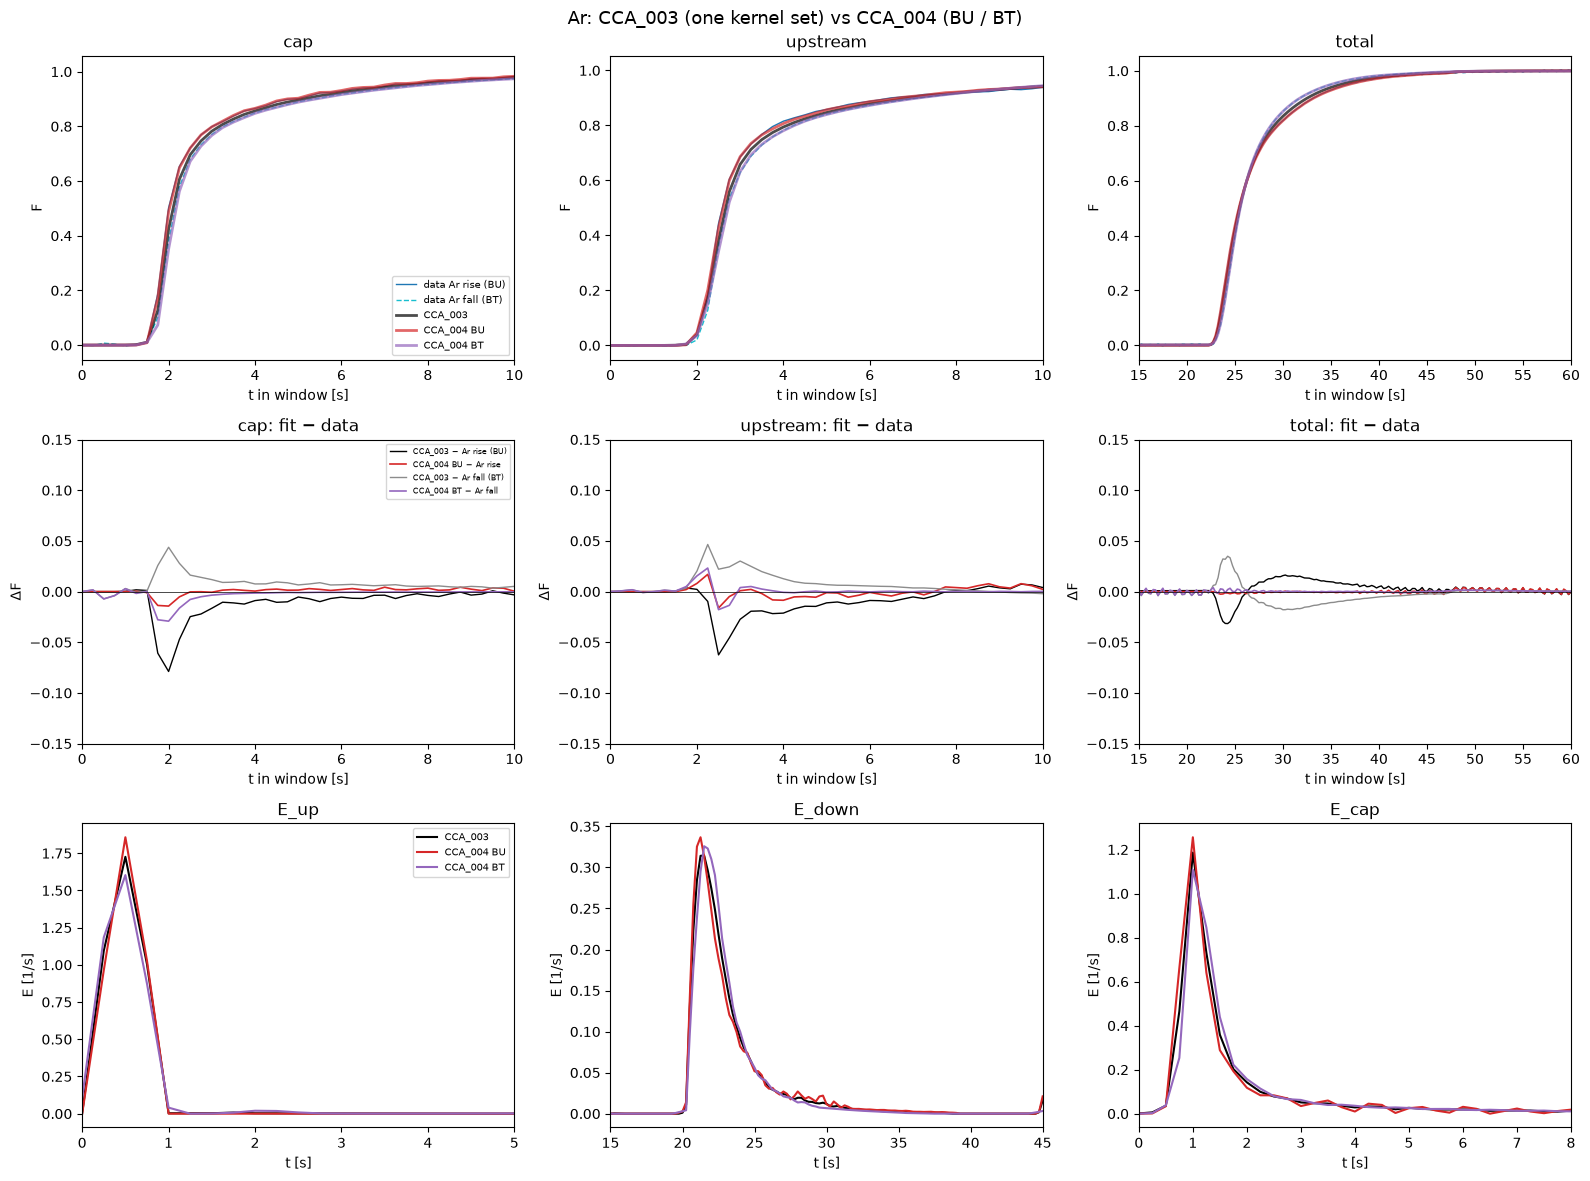

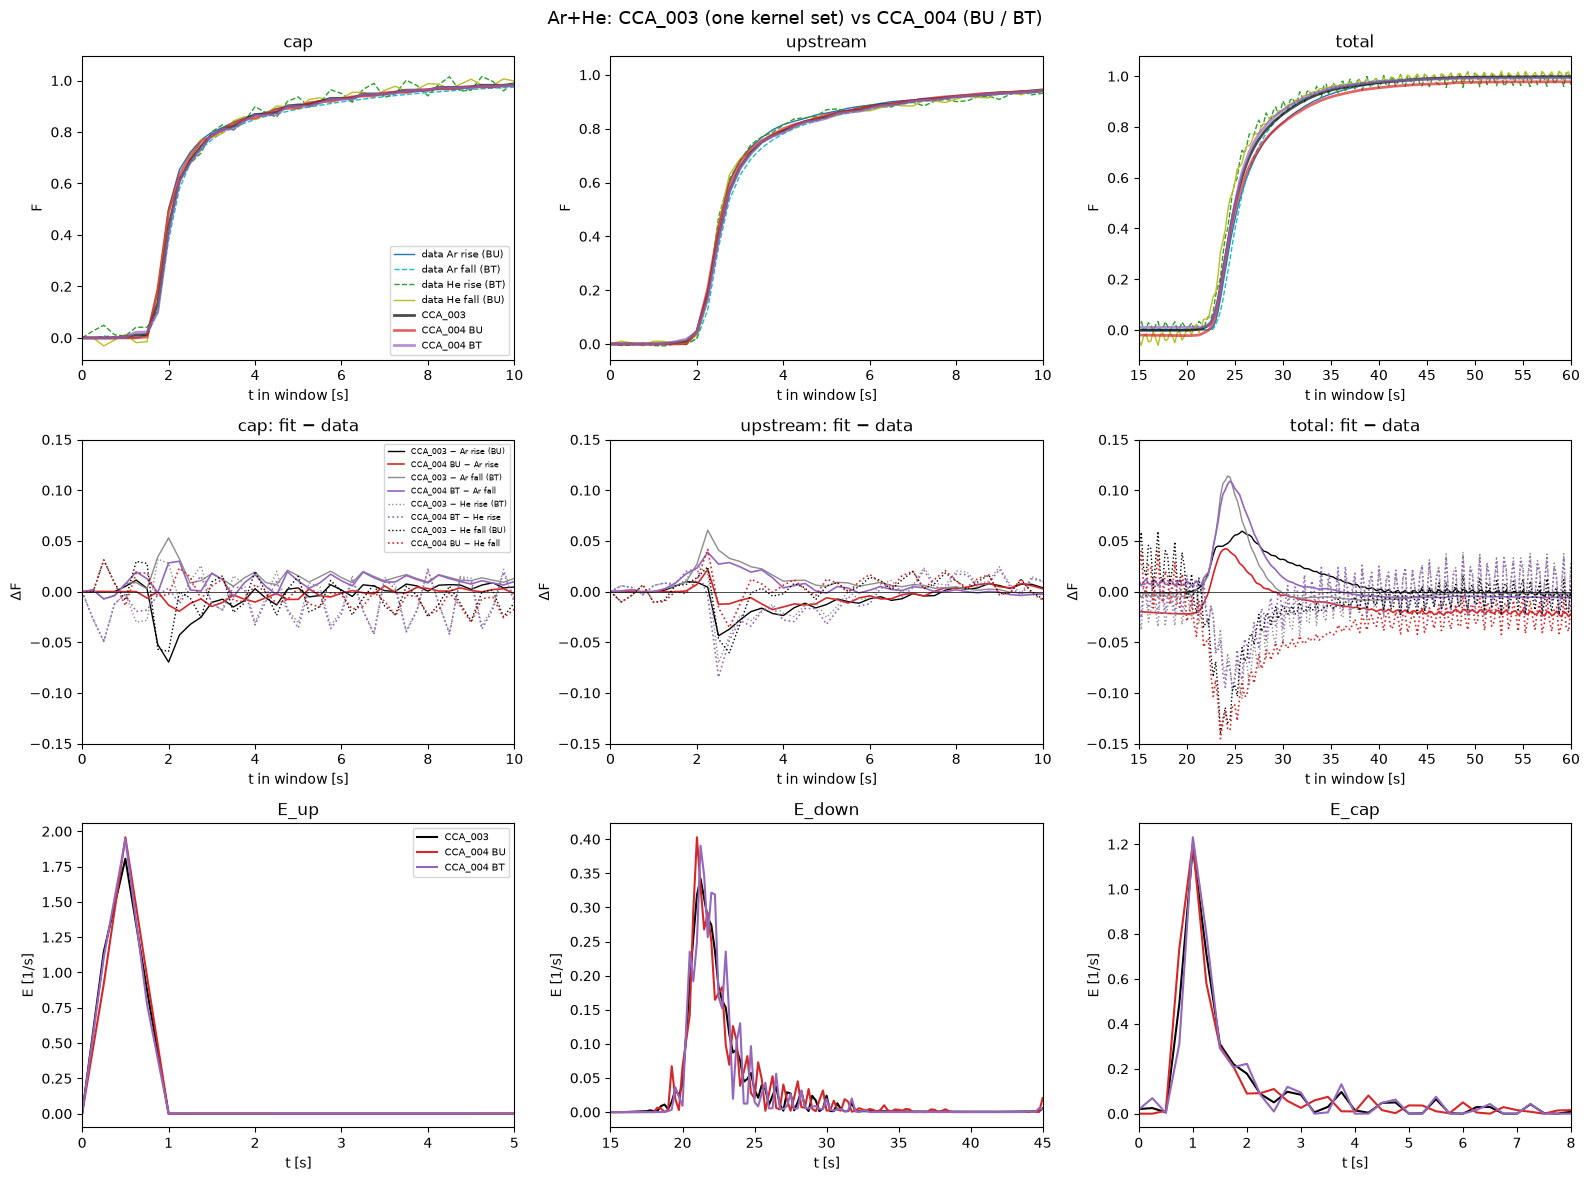

In [7]:
XLIM = {"cap": (0, 10), "upstream": (0, 10), "total": (15, 60)}
KLIM = (("E_up", (0, 5)), ("E_down", (15, 45)), ("E_cap", (0, 8)))
GCOL = {"Ar rise": "C0", "Ar fall": "C9", "He rise": "C2", "He fall": "C8"}
KCOL = {"CCA_003": "k", "CCA_004 BU": "C3", "CCA_004 BT": "C4"}
DCOL_003 = {"BU": "k", "BT": "0.55"}
figs = {}
for t in TRACER_SETS:
    if t not in complete:
        print(f"{LABEL[t]}: runs missing, no figure")
        continue
    own = [g for g in GROUPS if g[:2] in TRACER_SETS[t]]
    fig, ax = plt.subplots(3, 3, figsize=(16, 12))
    fig.suptitle(
        f"{LABEL[t]}: CCA_003 (one kernel set) vs CCA_004 (BU / BT)", fontsize=13
    )
    for j, s in enumerate(SECTIONS):
        tt = ref[f"t_out {s}"][0]
        for g in own:
            ax[0, j].plot(
                tt,
                data[s, g],
                c=GCOL[g],
                lw=1,
                ls="-" if DIRECTION[g] == "BU" else "--",
                label=f"data {g} ({DIRECTION[g]})",
            )
        for k in KSETS:
            ax[0, j].plot(tt, resp[t, k, s], c=KCOL[k], lw=2, alpha=0.7, label=k)
        for g in own:
            ls = "-" if g.startswith("Ar") else ":"
            ax[1, j].plot(
                tt,
                resp[t, "CCA_003", s] - data[s, g],
                c=DCOL_003[DIRECTION[g]],
                lw=1,
                ls=ls,
                label=f"CCA_003 − {g} ({DIRECTION[g]})",
            )
            k = f"CCA_004 {DIRECTION[g]}"
            ax[1, j].plot(
                tt,
                resp[t, k, s] - data[s, g],
                c=KCOL[k],
                lw=1.2,
                ls=ls,
                label=f"{k} − {g}",
            )
        ax[0, j].set(xlim=XLIM[s], title=s, xlabel="t in window [s]", ylabel="F")
        ax[1, j].axhline(0, c="k", lw=0.5)
        ax[1, j].set(
            xlim=XLIM[s],
            ylim=(-0.15, 0.15),
            title=f"{s}: fit − data",
            xlabel="t in window [s]",
            ylabel="ΔF",
        )
    for i, (n, xl) in enumerate(KLIM):
        tk = np.linspace(*KERNEL_TIMES[i], len(kernels[t, "CCA_003"][i]))
        for k in KSETS:
            ax[2, i].plot(tk, np.asarray(kernels[t, k][i]), c=KCOL[k], label=k)
        ax[2, i].set(title=n, xlim=xl, xlabel="t [s]", ylabel="E [1/s]")
    ax[0, 0].legend(fontsize=7)
    ax[1, 0].legend(fontsize=6)
    ax[2, 0].legend(fontsize=7)
    fig.tight_layout()
    figs[t] = fig

## 5. Kernels: BU vs BT

E(0) > 0 means part of the step passes instantly; ΣE·dt should be ≈ 1. Bed inlet = step ⊗ E_up (PTK_model_reconciliation
LOG F60): time after the step at which it reaches 0.5 and 0.9.

In [8]:
def bed_inlet(eu):
    t_s = np.arange(0, 35 + DT / 2, DT)
    step = (t_s >= T_STEP).astype(float)
    eu = np.asarray(eu)
    bed = (
        np.convolve(np.concatenate((np.zeros(eu.size - 1), step)), eu)[
            eu.size - 1 : eu.size - 1 + step.size
        ]
        * DT
    )
    return t_s, bed


rows = []
for (t, k), E in kernels.items():
    for i, (n, _) in enumerate(KLIM):
        tk = np.linspace(*KERNEL_TIMES[i], len(E[i]))
        e = np.asarray(E[i])
        rows.append(
            {
                "tracers": LABEL[t],
                "kernels": k,
                "kernel": n,
                "E(0) [1/s]": e[0],
                "ΣE·dt": e.sum() * DT,
                "mean t [s]": (tk * e).sum() / e.sum(),
                "t of max [s]": tk[np.argmax(e)],
            }
        )
    t_s, bed = bed_inlet(E[UP])
    rows.append(
        {
            "tracers": LABEL[t],
            "kernels": k,
            "kernel": "bed inlet",
            **crossings(t_s, bed),
        }
    )
kt = pd.DataFrame(rows)
display(
    kt[kt.kernel != "bed inlet"]
    .pivot_table(
        index=["tracers", "kernels"],
        columns="kernel",
        values=["mean t [s]", "ΣE·dt", "E(0) [1/s]"],
        sort=False,
    )
    .style.format(precision=3)
)
kt[kt.kernel == "bed inlet"].set_index(["tracers", "kernels"])[
    ["t10", "t50", "t90"]
].style.format(precision=2).set_caption("bed inlet, s after the step")

In [9]:
rows = []
for t in complete:
    m = kt[(kt.tracers == LABEL[t]) & (kt.kernel != "bed inlet")].set_index(
        ["kernels", "kernel"]
    )["mean t [s]"]
    for n, _ in KLIM:
        rows.append(
            {
                "tracers": LABEL[t],
                "kernel": n,
                "mean t BU − BT [s]": m["CCA_004 BU", n] - m["CCA_004 BT", n],
                "mean t CCA_003 [s]": m["CCA_003", n],
            }
        )
pd.DataFrame(rows).pivot_table(
    index="tracers", columns="kernel", values="mean t BU − BT [s]", sort=False
).style.format("{:+.3f}").set_caption("mean residence time, BU − BT")

kernel,E_up,E_down,E_cap
tracers,,,
He,+0.091,+1.068,-0.044
Ar,+0.067,+0.388,-0.176
Ar+He,+0.038,+1.030,-0.094


## 6. Summary per tracer set

Largest max |ΔF| over the groups of each tracer set's tracers, per section.

In [10]:
(
    quality.groupby(["tracers", "kernels", "section"])["max"]
    .max()
    .unstack("section")[list(SECTIONS)]
    .reindex([(LABEL[t], o) for t in complete for o in order])
    .style.format("{:.3f}")
    .background_gradient(axis=None, cmap="Reds")
)